In [2]:
from datasets.Harmonized_Datasets import harmonize
import pandas as pd 
import numpy as np 
from scipy.stats import fisher_exact
from statsmodels.stats.contingency_tables import mcnemar
import statsmodels.api as sm

In [3]:
mf_ad = harmonize()["Moffitt"]

/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!
DeCampos Annotated data found!
Number of Harmonized Genes: 18672


In [4]:
best_model_results = pd.read_csv("../../outputs/best_model_cv_predictions.csv").set_index('samples')

In [5]:
moffitt_observations_df = mf_ad.obs.loc[best_model_results.index]
moffitt_observations_df = moffitt_observations_df[moffitt_observations_df['t11_14'].notna()]

In [6]:
moffitt_observations_df[['y_pred', 'y_prob', 'y_true']] = best_model_results[['y_pred', 'y_prob', 'y_true']]

In [7]:
moffitt_observations_df['model_correct'] = (moffitt_observations_df['y_pred'] == moffitt_observations_df['y_true'])

moffitt_observations_df['t11_14_correct'] = (moffitt_observations_df['t11_14'] == moffitt_observations_df['y_true'])

In [8]:
# make contingency tables
mcn_ct = pd.crosstab(moffitt_observations_df['model_correct'], moffitt_observations_df['t11_14_correct'])

ct_true_labels = pd.crosstab(moffitt_observations_df['y_true'], moffitt_observations_df['t11_14'])

ct_pred_labels = pd.crosstab(moffitt_observations_df['y_pred'], moffitt_observations_df['t11_14'])


In [9]:
mcn_ct

t11_14_correct,False,True
model_correct,,
False,9,5
True,11,29


In [10]:
mcnemar(mcn_ct, exact=True).pvalue

np.float64(0.210113525390625)

In [11]:
fisher_exact(ct_true_labels)

SignificanceResult(statistic=np.float64(4.078431372549019), pvalue=np.float64(0.08796878847886003))

In [12]:
fisher_exact(ct_pred_labels)

SignificanceResult(statistic=np.float64(18.666666666666668), pvalue=np.float64(0.001398294411967163))

In [13]:
y = moffitt_observations_df['ABT-199']
model_1 = sm.OLS(y, sm.add_constant(moffitt_observations_df['t11_14'].astype(bool))).fit(cov_type='HC3')
model_2 = sm.OLS(y, sm.add_constant(moffitt_observations_df['y_prob'])).fit(cov_type='HC3')


model_3 = sm.OLS(y, sm.add_constant(np.column_stack([ moffitt_observations_df['t11_14'].astype(bool), moffitt_observations_df['y_prob']]))).fit(cov_type="HC3")

In [14]:
model_1.pvalues.iloc[1]

np.float64(0.010593426745400522)

In [15]:
print(f"r2: {model_1.rsquared:.6f}, p: {model_1.pvalues.iloc[1]:.6f}")


r2: 0.147762, p: 0.010593


In [16]:
print(f"r2: {model_2.rsquared:.6f}, p: {model_2.pvalues.iloc[1]:.6f}")

r2: 0.226478, p: 0.000001


In [17]:
model_3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                ABT-199   R-squared:                       0.271
Model:                            OLS   Adj. R-squared:                  0.242
Method:                 Least Squares   F-statistic:                     12.37
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           4.16e-05
Time:                        19:30:22   Log-Likelihood:                -225.47
No. Observations:                  54   AIC:                             456.9
Df Residuals:                      51   BIC:                             462.9
Df Model:                           2                                         
Covariance Type:                  HC3                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         97.0254      4.018     24.147      0.000      89.150     104.901
x1           -10.5135      7.277     -1.445      0.149     -24.776       3.749
x2           -30.3169      8.793     -3.448      0.001     -47.550     -13.084
==============================================================================
Omnibus:                       12.826   Durbin-Watson:                   1.951
Prob(Omnibus):                  0.002   Jarque-Bera (JB):               14.097
Skew:                          -0.983   Prob(JB):                     0.000869
Kurtosis:                       4.550   Cond. No.                         5.90
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

In [ ]:
model_3.prob

In [24]:
summary = {
    
}

models = {  't(11;14) status': model_1,
            'ML probability': model_2,
            't(11;14) status + ML probability': model_3
}

for key in models:
    model = models[key]
    summary[key] = {'R squared': model.rsquared, 'p-value': model.f_pvalue}

summary_df = pd.DataFrame(summary).T

In [25]:
summary_df

,R squared,p-value
t(11;14) status,0.147762,0.013556
ML probability,0.226478,0.000011
t(11;14) status + ML probability,0.270628,0.000042


Text(0.5, 1.0, 'Regression coefficeints for drug response (AUC)')

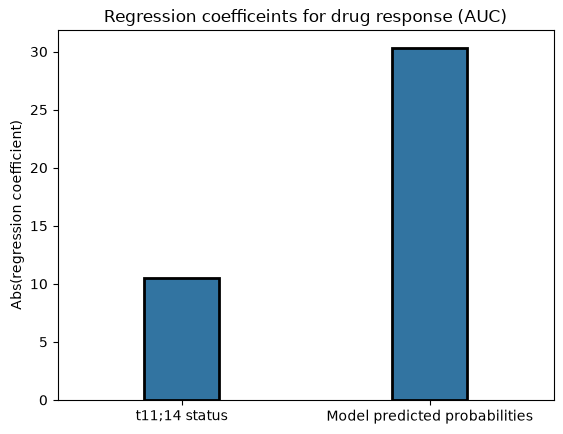

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
coeffs = {"t11;14 status": abs(model_3.params['x1']), "Model predicted probabilities": abs(model_3.params['x2'])}

sns.barplot(coeffs, orient='v', width=0.3, lw=2, edgecolor='k')

plt.ylabel('Abs(regression coefficient)')
plt.title("Regression coefficeints for drug response (AUC)")
#plt.axhline(y=0, color='k', ls='--')

In [36]:
# Does ML probability add anything beyond t(11;14)? (model_3 vs model_1)

pd.DataFrame({"t(11;14) beyond ML": model_3.compare_f_test(model_2), "ML beyond t(11;14)": model_3.compare_f_test(model_1)}, index=["F", "p-value", "df_diff"]).T


/tmp/ipykernel_66046/1810793513.py:3: InvalidTestWarning: F test for comparison is likely invalid with robust covariance, proceeding anyway
  pd.DataFrame({"t(11;14) beyond ML": model_3.compare_f_test(model_2), "ML beyond t(11;14)": model_3.compare_f_test(model_1)}, index=["F", "p-value", "df_diff"]).T
/tmp/ipykernel_66046/1810793513.py:3: InvalidTestWarning: F test for comparison is likely invalid with robust covariance, proceeding anyway
  pd.DataFrame({"t(11;14) beyond ML": model_3.compare_f_test(model_2), "ML beyond t(11;14)": model_3.compare_f_test(model_1)}, index=["F", "p-value", "df_diff"]).T


,F,p-value,df_diff
t(11;14) beyond ML,3.087129,0.084916,1.0
ML beyond t(11;14),8.591241,0.005045,1.0
